# **Bank Marketing Data Analysis**
Understanding Customer Balance and Marketing Calls

Dataset: Bank Marketing Data

Group-13

KHALIL MD EBRAHIM-24229546

JOY MD KAYEF AHMED-24229542

TAKBIR MOHAMMAD-24229565


**Research Question:**

Does average account balance differ between customer's different age group (young under 25 ,adult 25-45 and old older than 45) & Which age group the authority should target for campaign?

**Hypothesis:** Average balance differ across customer's different age group & adult should be targated.

## **1.Explaining the data**







In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_parquet("hf://datasets/cestwc/bank-marketing/data/train-00000-of-00001-f26fa3adaf6dfdf2.parquet")

# 1. Dataset Shape
print("=== Dataset Shape ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

# 2. General Info (Column types & Missing values summary)
print("=== Column Info & Missing Values ===")
df.info()
print("\n")

# 3. Duplicate Rows Count
print("=== Duplicate Rows ===")
duplicates = df.duplicated().sum()
print(f"Number of dupl as icate rows: {duplicates}\n")

# 4. Descriptive Statistics
print("=== Descriptive Statistics ===")
display(df.describe(include='all'))

=== Dataset Shape ===
Rows: 45211, Columns: 17

=== Column Info & Missing Values ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  int64
 2   marital    45211 non-null  int64
 3   education  45211 non-null  int64
 4   default    45211 non-null  int64
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  int64
 7   loan       45211 non-null  int64
 8   contact    45211 non-null  int64
 9   day        45211 non-null  int64
 10  month      45211 non-null  int64
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  int64
 16  y          45211 non-null  int64
dtypes: int64(17)
memory usage: 5.9 MB


=== Duplicate Rows ===
Number of duplicate 

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,4.339762,1.167725,1.224813,0.018027,1362.272058,0.555838,0.160226,0.640242,15.806419,5.144655,258.163080,2.763841,857.565283,0.580323,2.559974,0.116985
std,10.618762,3.272657,0.608230,0.747997,0.133049,3044.765829,0.496878,0.366820,0.897951,8.322476,2.408034,257.527812,3.098021,303.245691,2.303441,0.989059,0.321406
min,18.000000,0.000000,0.000000,0.000000,0.000000,-8019.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,33.000000,1.000000,1.000000,1.000000,0.000000,72.000000,0.000000,0.000000,0.000000,8.000000,4.000000,103.000000,1.000000,999.000000,0.000000,3.000000,0.000000
50%,39.000000,4.000000,1.000000,1.000000,0.000000,448.000000,1.000000,0.000000,0.000000,16.000000,5.000000,180.000000,2.000000,999.000000,0.000000,3.000000,0.000000
75%,48.000000,7.000000,2.000000,2.000000,0.000000,1428.000000,1.000000,0.000000,2.000000,21.000000,7.000000,319.000000,3.000000,999.000000,0.000000,3.000000,0.000000
max,95.000000,11.000000,2.000000,3.000000,1.000000,102127.000000,1.000000,1.000000,2.000000,31.000000,11.000000,4918.000000,63.000000,999.000000,275.000000,3.000000,1.000000


**Key variables**

*   Age: The age of the customers(years).
*   Job: Job category.


*   Balance: The customer’s average yearly account balance.
*   Duration: The length of the last marketing phone call(seconds).


*  Campaign: The number of contacts made with the customer during campaign.










**Q1. Multiple Choice**

Which two variables should discuss in our analysis?

A. Age

B. Job category

C. Account balance

D. Campaign

# **2. Inspect data quality**

We check before cleaning:

missing values;

duplicate rows;

data types;

ranges of numerical variables;

category values.

We do not silently delete anything.

In [ ]:
import pandas as pd

# 1. Check Missing Values
print("=== Missing Values Per Column ===")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found.")
print("\n")

# 2. Check Duplicate Rows
print("=== Duplicate Rows ===")
duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates}\n")

# 3. Check Data Types
print("=== Data Types ===")
display(df.dtypes.to_frame(name='Data Type'))
print("\n")

# 4. Check Ranges of Numerical Variables (Min to Max)
print("=== Ranges of Numerical Variables ===")
numerical_cols = df.select_dtypes(include=['number']).columns
ranges_df = pd.DataFrame({
    'Min': df[numerical_cols].min(),
    'Max': df[numerical_cols].max()
})
display(ranges_df)
print("\n")

# 5. Check Category Values / Unique Value Counts
print("=== Unique Value Counts Per Column ===")
unique_counts = df.nunique().to_frame(name='Unique Values')
display(unique_counts)

=== Missing Values Per Column ===


'No missing values found.'



=== Duplicate Rows ===
Total duplicate rows: 0

=== Data Types ===


,Data Type
age,int64
job,int64
marital,int64
education,int64
default,int64
balance,int64
housing,int64
loan,int64
contact,int64
day,int64




=== Ranges of Numerical Variables ===


,Min,Max
age,18,95
job,0,11
marital,0,2
education,0,3
default,0,1
balance,-8019,102127
housing,0,1
loan,0,1
contact,0,2
day,1,31




=== Unique Value Counts Per Column ===


,Unique Values
age,77
job,12
marital,3
education,4
default,2
balance,7168
housing,2
loan,2
contact,3
day,31


Q2: Does average account balance differ between customer's different age group (young under 25 ,adult 25-45 and old older than 45)?

*   True
*   False

#**3.Testing Hypothesis:**











In [ ]:
def categorize_age(age):
    """
    Categorize ages into three specified groups:
    - Young: under 25
    - Adult: 25 to 45 (inclusive)
    - Old: older than 45
    """
    if age < 25:
        return 'Young (<25)'
    elif 25 <= age <= 45:
        return 'Adult (25-45)'
    else:
        return 'Old (>45)'

# Quick demonstration
test_ages = [18, 25, 35, 45, 52]
for age in test_ages:
    print(f"Age: {age} -> Category: {categorize_age(age)}")

Age: 18 -> Category: Young (<25)
Age: 25 -> Category: Adult (25-45)
Age: 35 -> Category: Adult (25-45)
Age: 45 -> Category: Adult (25-45)
Age: 52 -> Category: Old (>45)


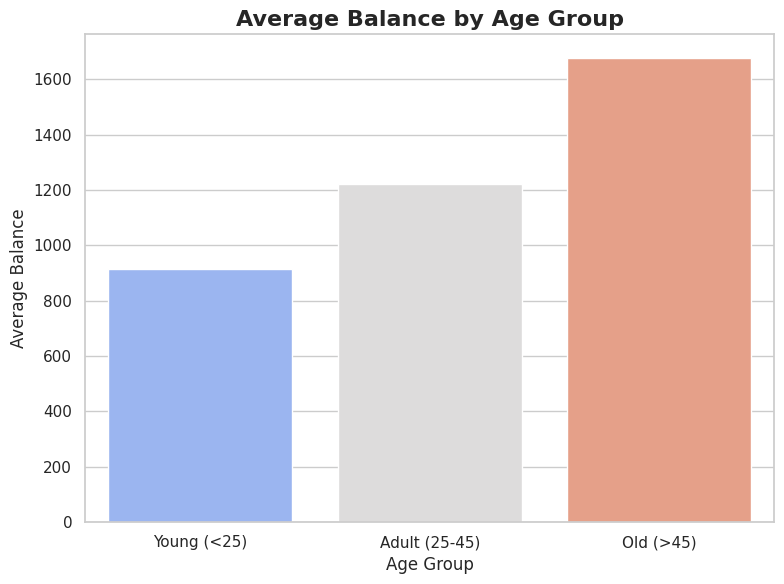

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset if not already in memory
try:
    df
except NameError:
    df = pd.read_parquet("hf://datasets/cestwc/bank-marketing/data/train-00000-of-00001-f26fa3adaf6dfdf2.parquet")

# Define the three age groups
def categorize_age(age):
    if age < 25:
        return 'Young (<25)'
    elif age <= 45:
        return 'Adult (25-45)'
    else:
        return 'Old (>45)'

# Create age group column
df['age_group'] = df['age'].apply(categorize_age)

# Group by 'age_group' and calculate average balance
age_group_balance = df.groupby('age_group')['balance'].mean().reindex(['Young (<25)', 'Adult (25-45)', 'Old (>45)']).reset_index()

# Set seaborn theme
sns.set_theme(style="whitegrid")

# Plot the bar graph
plt.figure(figsize=(8, 6))
sns.barplot(x='age_group', y='balance', data=age_group_balance, palette='coolwarm', hue='age_group', legend=False)

# Add titles and labels
plt.title('Average Balance by Age Group', fontsize=16, fontweight='bold')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Average Balance', fontsize=12)

plt.tight_layout()
plt.show()

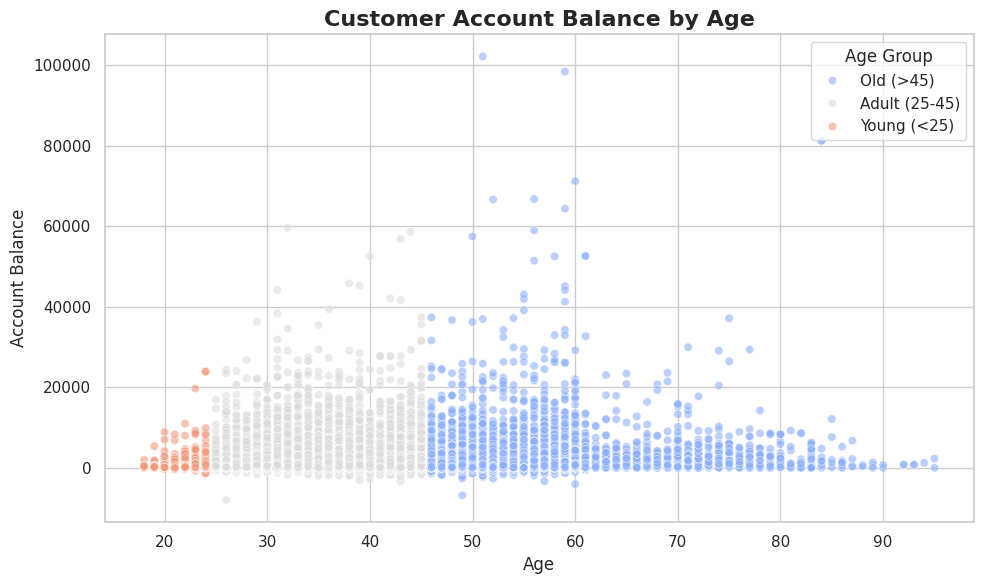

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset if not already in memory
try:
    df
except NameError:
    df = pd.read_parquet("hf://datasets/cestwc/bank-marketing/data/train-00000-of-00001-f26fa3adaf6dfdf2.parquet")

# Define the age groups categorization function
def categorize_age(age):
    if age < 25:
        return 'Young (<25)'
    elif age <= 45:
        return 'Adult (25-45)'
    else:
        return 'Old (>45)'

# Create age group column if not already present
if 'age_group' not in df.columns:
    df['age_group'] = df['age'].apply(categorize_age)

# Set seaborn theme
sns.set_theme(style="whitegrid")

# Plot the scatter plot to visualize Age vs Balance
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='balance', hue='age_group', palette='coolwarm', alpha=0.6)

# Add titles and labels
plt.title('Customer Account Balance by Age', fontsize=16, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Account Balance', fontsize=12)
plt.legend(title='Age Group')

plt.tight_layout()
plt.show()

Q3 — The older age group had a higher average account balance than the
younger age group in our analysis.

* True  
 * False

Q4.Our analysis proves that age directly causes a customer's account balance to increase.

* True  
* False

Q5: Which age group the authority should target for campaign?

A. Young

B. Adult

C. Older

D. A & C

# **4. Conclusion & Limitations**

### **Conclusion**
Based on our analysis of the bank marketing dataset, we observed a clear relationship between customer age groups and their average account balances.As old age group has higher account balance so authority should target them for campaign.

These findings do not fully support our hypothesis that average account balance differs across different age groups, but older cohorts generally holding significantly higher balances.

---



### **Limitations of the Analysis (Methodological)**
Below are the limitations of this analysis, focusing purely on methodology and analytical constraints rather than dataset quality or size:

1.Shows patterns, not causes

2.Confounding Variables

3.Age groups are our choice
